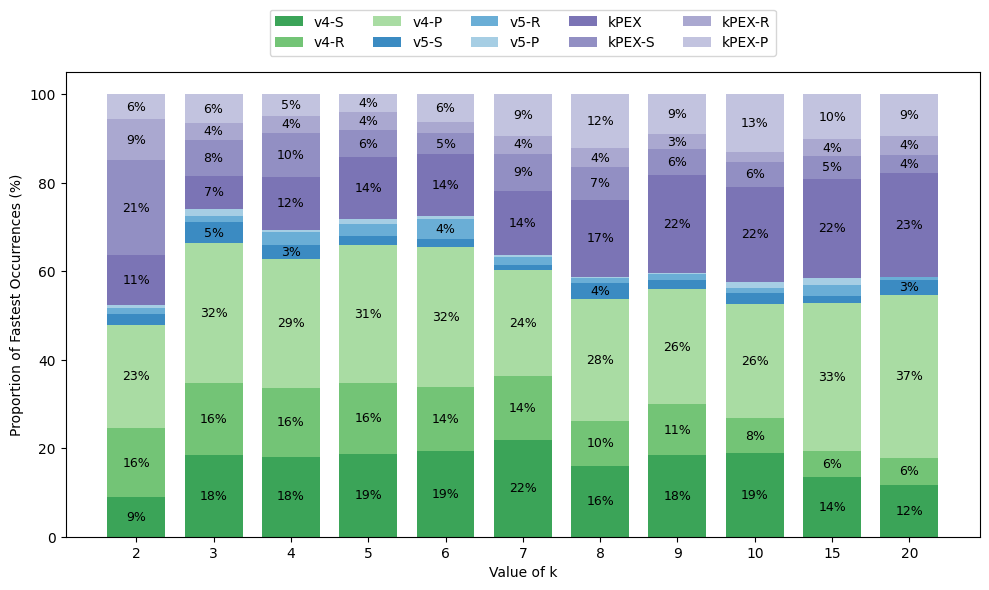

In [13]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

# -------------------------------------------------
# 1. Replace "x" with 1800 in ORIGINAL df (in place)
# -------------------------------------------------

file_path = "results-filtered-dataset.csv"

# Read the first sheet
# df = pd.read_excel(file_path)
df = pd.read_csv(file_path)

sp_noAltRB = ["v4-S", "v4-R", "v4-P"]
sp_AltRB = ["v5-S", "v5-R", "v5-P"]
dense = ["kPEX", "kPEX-S", "kPEX-R", "kPEX-P"]


sparse = sp_noAltRB + sp_AltRB
all_algos = sparse + dense

df[all_algos] = df[all_algos].replace("x", 1800).apply(pd.to_numeric)


k_values = [2,3,4,5,6,7,8,9,10,15,20]

# store percentages
results = {algo: [] for algo in all_algos}

for k in k_values:

    df_k = df[df["k"] == k]

    if len(df_k) == 0:
        for algo in all_algos:
            results[algo].append(0)
        continue

    winners = df_k[all_algos].idxmin(axis=1)

    win_counts = winners.value_counts()
    total = len(df_k)

    for algo in all_algos:
        wins = win_counts.get(algo, 0)
        percent = (wins / total) * 100
        results[algo].append(percent)

# convert to dataframe for easier plotting
res_df = pd.DataFrame(results, index=k_values)

# ---- plotting ----
groups = {
    "sp_noAltRB": sp_noAltRB,
    "sp_AltRB": sp_AltRB,
    "dense": dense
}

# choose visually pleasing colormaps
cmaps = {
    "sp_noAltRB": plt.cm.Greens,
    "sp_AltRB": plt.cm.Blues,
    "dense": plt.cm.Purples
}

colors = {}

for g, algos in groups.items():
    cmap = cmaps[g]
    
    # avoid very dark tones and sample dark→light
    shades = cmap(np.linspace(0.65, 0.35, len(algos)))
    
    for algo, shade in zip(algos, shades):
        colors[algo] = shade
        
x = np.arange(len(k_values))   # evenly spaced bar positions

fig, ax = plt.subplots(figsize=(10,6))

bottom = np.zeros(len(k_values))
black_font_algos = {"UMKP-S"}
for algo in all_algos:
    vals = res_df[algo].values

    bars = ax.bar(
        x,
        vals,
        bottom=bottom,
        label=algo,
        width=0.75,
        color=colors[algo]
    )

    for i, v in enumerate(vals):
        if v > 3:

            text_color = "white" if algo in black_font_algos else "black"

            ax.text(
                x[i],
                bottom[i] + v/2,
                f"{v:.0f}%",
                ha='center',
                va='center',
                fontsize=9,
                color=text_color
            )

    bottom += vals

ax.set_xlabel("Value of k")
ax.set_ylabel("Proportion of Fastest Occurrences (%)")
# ax.set_title("Algorithm Wins by k")

ax.set_xticks(x)
ax.set_xticklabels(k_values)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=5
)

plt.tight_layout()
# plt.show()